# 1.Data Understanding - Telco Customer Churn
In dit notebook onderzoek ik de Telco Customer Churn-dataset. Ik beschrijf de data, controleer de kwaliteit en bekijk de eerste verbanden met churn.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("../Sprint 1/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [18]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
df.shape

(7043, 21)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

De dataset bevat 7.043 klanten en 21 klommen. Elke rij is een klant, de kolommen gaan over het klantprofiel, de diensten, het contract en de betaling. De kolom churn geeft aan of een klant is vertrokken.

Wat me opvalt is (Totalcharges) is opgeslagen als tekst terwijl het een bedrag moet zijn. Dit onderzoek ik vreder bij de datakwaliteit.

## 2.Datakwaliteit
Voordat ik ga analyseren, contrleer ik of de data compleet, uniek en logisch is.

In [21]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [22]:
print("Dubbele rijen:", df.duplicated().sum())
print("Dubbele klantnummers:",df["customerID"].duplicated().sum())

Dubbele rijen: 0
Dubbele klantnummers: 0


In [23]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Lege TotalCharges:", df["TotalCharges"].isna().sum())

Lege TotalCharges: 11


In [24]:
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [25]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Lege TotalCharges na invullen:", df["TotalCharges"].isna().sum())

Lege TotalCharges na invullen: 0


In [26]:
for kolom in df.select_dtypes(include="str").columns:
    if kolom != "customerID":
        print(kolom, list(df[kolom].unique()))

gender ['Female', 'Male']
Partner ['Yes', 'No']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No phone service', 'No', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'Yes', 'No internet service']
OnlineBackup ['Yes', 'No', 'No internet service']
DeviceProtection ['No', 'Yes', 'No internet service']
TechSupport ['No', 'Yes', 'No internet service']
StreamingTV ['No', 'Yes', 'No internet service']
StreamingMovies ['No', 'Yes', 'No internet service']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['Yes', 'No']
PaymentMethod ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn ['No', 'Yes']


In [27]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


### Conclusie datakwaliteit

**Doel**:voordat ik ga analyseren, controleer ik of de data compleet, uniek en logisch is. Als de data fouten bevat, kloppen mijn conclusies over churn later ook niet.

**1. Ontbrekende gegevens**
Ik heb per kolom geteld hoeveel cellen leeg zijn, omdat lege cellen berekeningen verstoren. Op het eerste gezicht ontbrak er niets, maar bij TotalCharges bleek dat later wel zo te zijn (zie punt 3).

**2. Dubbele klanten**
Ik heb gecontroleerd of klanten dubbel in de data staan, omdat ze anders dubbel meetellen in de churnpercentages. Elke klant komt precies één keer voor.

**3. TotalCharges (totaal betaald bedrag)**
Deze kolom was opgeslagen als tekst in plaats van als getal, waardoor Python er niet mee kon rekenen. Daarom heb ik de kolom omgezet naar getallen. Daarbij bleek dat 11 klanten geen bedrag hadden, maar een lege spatie. Alle 11 waren 0 maanden klant: nieuwe klanten die nog niets hebben betaald. Ik heb hun bedrag op 0 gezet in plaats van ze te verwijderen, zodat alle 7.043 klanten in de analyse blijven.

**4. Tekstkolommen**
Ik heb per kolom bekeken welke antwoorden erin voorkomen, om spelfouten zoals "Yes" en "yes" door elkaar uit te sluiten. Python ziet die namelijk als twee verschillende groepen. Alle antwoorden zijn netjes. "No internet service" bij zes diensten is geen fout: de klant heeft geen internet en kan die dienst dus niet afnemen.

**5. Getallen**
Ik heb de kleinste, grootste en gemiddelde waarden bekeken om onmogelijke waarden uit te sluiten. Alles ligt binnen logische grenzen:
- Klantduur: 0 tot 72 maanden, gemiddeld 32.
- Maandelijkse kosten: 18,25 tot 118,75 dollar, gemiddeld 64,76.
- Totaal betaald: 0 tot 8.684,80 dollar. Het gemiddelde (2.280) ligt veel hoger dan het middelste bedrag (1.395), omdat een kleine groep langjarige klanten veel heeft betaald.
- SeniorCitizen: 16% is 65 jaar of ouder. Deze kolom gebruikt 0/1 in plaats van "Yes"/"No", daar houd ik rekening mee.


**6. Eindeconclusie:**
De dataset is van goede kwaliteit. Het enige probleem waren 11 nieuwe klanten zonder totaalbedrag, dat ik heb opgelost door 0 in te vullen. De data is betrouwbaar genoeg om te onderzoeken welke klantkenmerken samenhangen met churn. 

### 3.Doelvariabele Churn:
In deze stap bekijk ik hoeveel klanten zijn vertrokken en hoeveel er zijn gebleven. Dit is de kolom die ik in mijn project wil begrijpen.

In [29]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [32]:
(df["Churn"].value_counts(normalize=True) * 100).round(1)

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

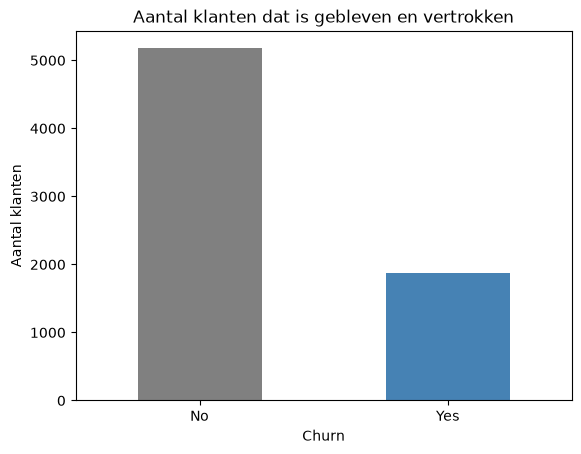

In [33]:
df["Churn"].value_counts().plot(kind="bar", color=["grey", "steelblue"])
plt.title("Aantal klanten dat is gebleven en vertrokken")
plt.xlabel("Churn")
plt.ylabel("Aantal klanten")
plt.xticks(rotation=0)
plt.show()

### Conclusie doelvariable churn
**Doel** Ik wilde weten hoeveel klanten vertrekken, omdat dit het probleem is waar mijn project over gaat.

**Uitkomst** van de 7.043 klanten zijn er 1.869 vertrokken (26,5%) en 5.174 gebleven (73,5%). Ruim een op de vier klanten vetrekt. Dat laat zien dat churn een groot probleem is voor het bedrijf.

**Wat betekent dit voor mijn analyse?**
- Er zijn bijna drie keer zoveel klanten die bijlven als klanten die vertrekken. De groepen zijn dus niet even groot.
- Daarom vergelijk ik in de volgende stap geen aantallen maar precentages. een grote groep heeft nameklijk altijd meer vertrekkers, ook als het risico in die groep niet hoger is.
- de 26,5% gebruik ik als gemiddelde om mee te vergelijken. ligt het precentage vertrekkers in een groep klanten duidelijk hoger dan 26,5%? dan is dat een groep met een verhoogd risico.

#### 4. Verbanden tussen klantkenmerken en churn
In deze stap onderzoek ik per klantkenmerk welk precentage van de klanten vertrekt. Dat verglijk ik met het gemiddelde van 26,5%. Ligt het percentage in een groep duidelijk hoger, dan hangt dat kenmerk samen met churn


In [34]:
df["churn_num"] = (df["Churn"] == "Yes").astype(int)
df[["Churn", "churn_num"]].head()

,Churn,churn_num
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [35]:
gemiddelde = df["churn_num"].mean() * 100
print("Gemiddelde churn:", round(gemiddelde, 1), "%")

Gemiddelde churn: 26.5 %


In [37]:
def churn_per_groep(kolom):
    tabel = df.groupby(kolom, observed=True)["churn_num"].agg(["mean", "count"])
    tabel.columns = ["churn_pct", "aantal_klanten"]
    tabel["churn_pct"] = (tabel["churn_pct"] * 100).round(1)
    return tabel

def grafiek_churn(kolom, titel):
    pct = df.groupby(kolom, observed=True)["churn_num"].mean() * 100
    pct.plot(kind="bar", color="grey")
    plt.axhline(gemiddelde, color="red", linestyle="--", label=f"gemiddelde {gemiddelde:.1f}%")
    plt.title(titel)
    plt.ylabel("Churn (%)")
    plt.xticks(rotation=0)
    plt.legend()
    plt.show()

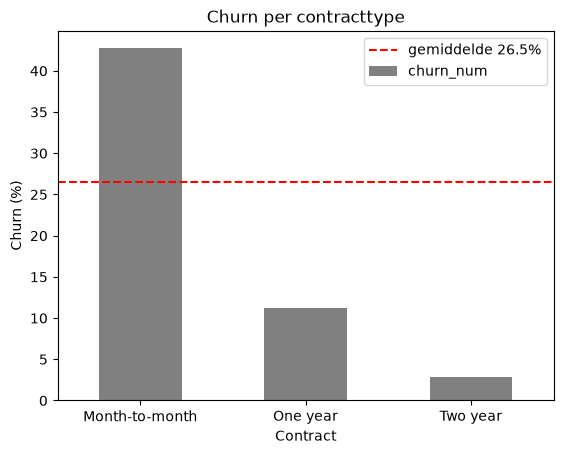

In [38]:
grafiek_churn("Contract", "Churn per contracttype")

In [39]:
df["klantduur_groep"] = pd.cut(df["tenure"],
                               bins=[-1, 6, 12, 24, 48, 72],
                               labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
churn_per_groep("klantduur_groep")

,churn_pct,aantal_klanten
klantduur_groep,,
0-6,52.9,1481
7-12,35.9,705
13-24,28.7,1024
25-48,20.4,1594
49-72,9.5,2239


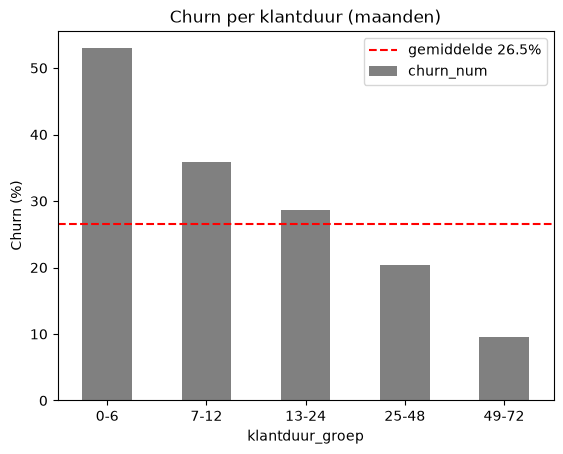

In [40]:
grafiek_churn("klantduur_groep", "Churn per klantduur (maanden)")

In [41]:
df["kosten_groep"] = pd.cut(df["MonthlyCharges"],
                            bins=[0, 35, 70, 90, 120],
                            labels=["<35", "35-70", "70-90", "90+"])
churn_per_groep("kosten_groep")

,churn_pct,aantal_klanten
kosten_groep,,
<35,10.9,1735
35-70,23.9,1725
70-90,37.8,1844
90+,32.8,1739


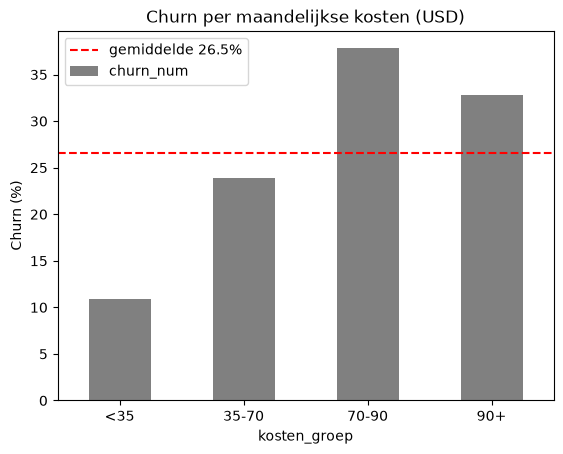

In [42]:
grafiek_churn("kosten_groep", "Churn per maandelijkse kosten (USD)")

### tussenconclusie: Contract, klantduur en kosten

**Constracttype** 
hangt sterk samen met churn. Klanten met een maandcontract vertrekken veel vaker (42,7%) dan gemiddeld (26,5%). bij een eenjarig contract is dat 11,3% en bij een tweejarig contract maar 2,8%. Waarschijnlijk komt dat doordat klanten met een maandcontract elke maand kunnen opzeggen.

**Klantduur**
hangt ook sterk samen met churn. Hoe korter iemand klant is, hoe vaker hij vertrekt. In de eerste zes maanden vertrekt 52,9% van de klanten, na vier jaar nog maar 9,5%. vooral nieuwe klanten hebben dus extra aandacht nodig.

**Maandelijkse kosten**
Hangen minder samen met churn. Klanten die meer dan 70 dollar per maand betalen, vetrekken vaker van dan gemiddeld (37,8% en 32,8%). Klanten die minder dan 35 dollar betalen, vertrekken weinig (10,9%)

(Dit zijn verbanden, geen oorzaken)



In [43]:
churn_per_groep("InternetService")

,churn_pct,aantal_klanten
InternetService,,
DSL,19.0,2421
Fiber optic,41.9,3096
No,7.4,1526


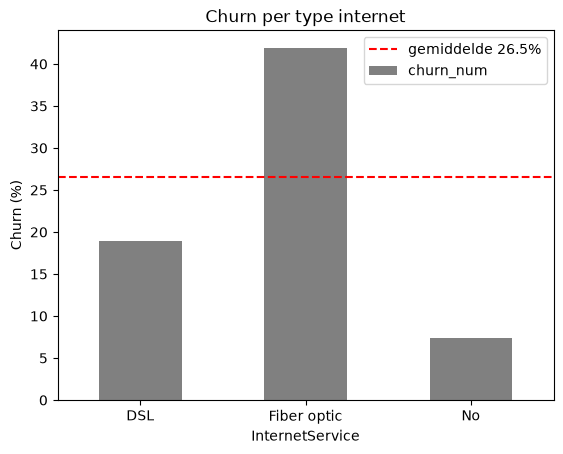

In [44]:
grafiek_churn("InternetService", "Churn per type internet")

In [45]:
diensten = ["OnlineSecurity", "TechSupport", "OnlineBackup",
            "DeviceProtection", "StreamingTV", "StreamingMovies"]

for dienst in diensten:
    print(dienst)
    print(churn_per_groep(dienst))
    print()

OnlineSecurity
                     churn_pct  aantal_klanten
OnlineSecurity                                
No                        41.8            3498
No internet service        7.4            1526
Yes                       14.6            2019

TechSupport
                     churn_pct  aantal_klanten
TechSupport                                   
No                        41.6            3473
No internet service        7.4            1526
Yes                       15.2            2044

OnlineBackup
                     churn_pct  aantal_klanten
OnlineBackup                                  
No                        39.9            3088
No internet service        7.4            1526
Yes                       21.5            2429

DeviceProtection
                     churn_pct  aantal_klanten
DeviceProtection                              
No                        39.1            3095
No internet service        7.4            1526
Yes                       22.5            2422


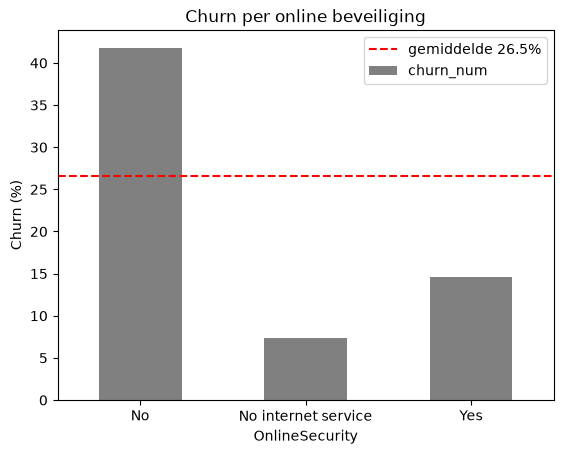

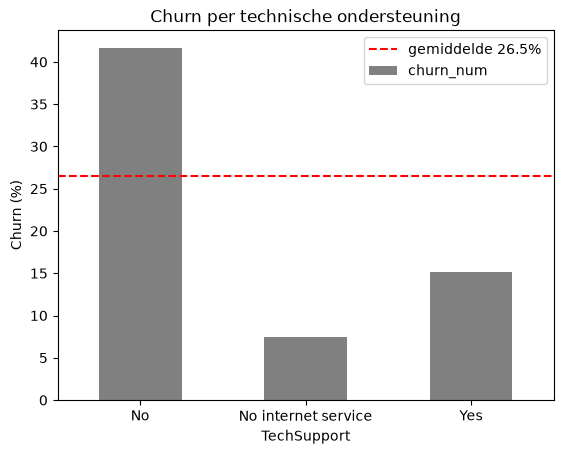

In [46]:
grafiek_churn("OnlineSecurity", "Churn per online beveiliging")
grafiek_churn("TechSupport", "Churn per technische ondersteuning")

In [47]:
churn_per_groep("PaymentMethod")

,churn_pct,aantal_klanten
PaymentMethod,,
Bank transfer (automatic),16.7,1544
Credit card (automatic),15.2,1522
Electronic check,45.3,2365
Mailed check,19.1,1612


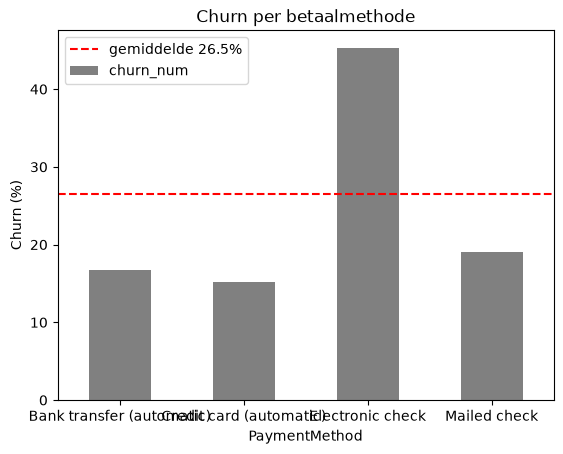

In [49]:
grafiek_churn("PaymentMethod", "Churn per betaalmethode")

In [50]:
churn_per_groep("PaperlessBilling")

,churn_pct,aantal_klanten
PaperlessBilling,,
No,16.3,2872
Yes,33.6,4171


In [52]:
for kenmerk in ["SeniorCitizen", "Partner", "Dependents", "gender"]:
    print(kenmerk)
    print(churn_per_groep(kenmerk))
    print()

SeniorCitizen
               churn_pct  aantal_klanten
SeniorCitizen                           
0                   23.6            5901
1                   41.7            1142

Partner
         churn_pct  aantal_klanten
Partner                           
No            33.0            3641
Yes           19.7            3402

Dependents
            churn_pct  aantal_klanten
Dependents                           
No               31.3            4933
Yes              15.5            2110

gender
        churn_pct  aantal_klanten
gender                           
Female       26.9            3488
Male         26.2            3555



In [53]:
pd.crosstab(df["Contract"], df["klantduur_groep"],
            values=df["churn_num"], aggfunc="mean").mul(100).round(1)

klantduur_groep,0-6,7-12,13-24,25-48,49-72
Contract,,,,,
Month-to-month,55.2,42.0,37.7,32.9,26.0
One year,10.3,10.6,8.1,10.6,12.9
Two year,0.0,0.0,0.0,2.2,3.3


In [54]:
kenmerken = ["Contract", "klantduur_groep", "kosten_groep", "InternetService",
             "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
             "StreamingTV", "StreamingMovies", "PhoneService", "MultipleLines",
             "PaymentMethod", "PaperlessBilling",
             "SeniorCitizen", "Partner", "Dependents", "gender"]

overzicht = []
for kenmerk in kenmerken:
    tabel = churn_per_groep(kenmerk)
    tabel = tabel.drop(["No internet service", "No phone service"], errors="ignore")
    overzicht.append({
        "kenmerk": kenmerk,
        "groep_hoogste_churn": tabel["churn_pct"].idxmax(),
        "hoogste_pct": tabel["churn_pct"].max(),
        "laagste_pct": tabel["churn_pct"].min()
    })

overzicht = pd.DataFrame(overzicht)
overzicht["verschil"] = (overzicht["hoogste_pct"] - overzicht["laagste_pct"]).round(1)
overzicht.sort_values("verschil", ascending=False)

,kenmerk,groep_hoogste_churn,hoogste_pct,laagste_pct,verschil
1,klantduur_groep,0-6,52.9,9.5,43.4
0,Contract,Month-to-month,42.7,2.8,39.9
3,InternetService,Fiber optic,41.9,7.4,34.5
12,PaymentMethod,Electronic check,45.3,15.2,30.1
4,OnlineSecurity,No,41.8,14.6,27.2
2,kosten_groep,70-90,37.8,10.9,26.9
5,TechSupport,No,41.6,15.2,26.4
6,OnlineBackup,No,39.9,21.5,18.4
14,SeniorCitizen,1,41.7,23.6,18.1
13,PaperlessBilling,Yes,33.6,16.3,17.3


### Conclusie verbanden met churn

**doel:** Ik wilde onderzoeken welke klantenkenmerken samenhangen met churn. Daarvoor heb ik per kenmerk berekend welke percentage van de klanten vertrekt en dat vergeleken met het gemiddelde van 26,5%

**Sterke verbanden:** (Verschil van meer dan 25 procent
- **Klantduur:** in de eerste 6 maanden vertrekt 52,9% van de klanten na 4 jaar nog maar 9,5%.
- **Contracttype:** Bij een maand contract vertrekt 42,7%, bij een twee jarig contract maar 2,8%.
- **Type internet:** klanten met glasvezel vertrekken vaker 41,9% dan klanten met DSL 19,0%.
- **Betaalmethoden:** klanten die met electronic check betalen, vertrekken vaker 45,3% dan klanten met een automatusche betaling 15-17%.
- **online beveiliging en technische ondersteuning:** klanten die deze dienst niet hebben vetrekken bijna drie keer zo vaak als klanten die ze wel hebben.
- **Maandelijkse kosten:** klanten die meer dan 70 dollar per maand betalen vertrekken vaker.



**Middelmatige verbanden:** ouderen (65+), klanten zonder partner of kinderen, klanten met een digitale factuur en klanten zonder back-up of apparaatbescherming vertrekken iets vaker  



**Contract en klantduur samen**: nieuwe klanten hebben vaak een maandcontract, dus deze twee kenmerken hangen met elkaar samen. De grootste risicogroep is klanten met een maandcontract die korter dan 6 maanden klkant zijn daar vertrekt 55,2%.

**### Wat betekent dit voor de cosutomer Retention tool?**
De kenmerken met een sterk verband zijn het meest bruikbaar om risico klanten te herkennen:
- Klantduur
- Contracttype
- type internet
- betaalmethode
- online beveiliging
- technische ondersteuning
- maandelijkse kosten.
